### **1. Анализ продаж: выручка по месяцам, рост к прошлому месяцу, средний чек, топ категорий**

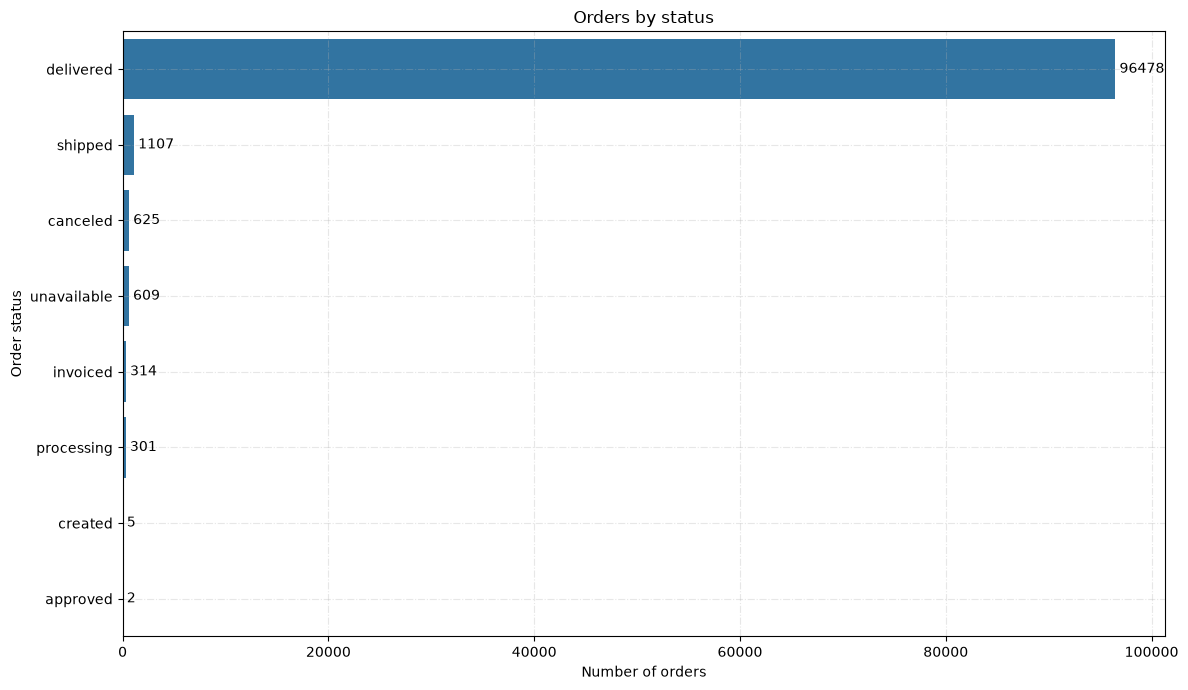

In [162]:
import seaborn as sns
import matplotlib.pyplot as plt

import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2://a111@localhost:5432/olist")

dt = pd.read_sql("SELECT order_status, COUNT(*) AS cnt FROM orders GROUP BY 1 ORDER BY 2 DESC", engine)

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=dt, x="cnt", y="order_status")
ax.bar_label(ax.containers[0], fmt="%d", padding=3) 
plt.grid(alpha=0.3, linestyle='-.')
plt.title("Orders by status")
plt.xlabel("Number of orders")
plt.ylabel("Order status")
plt.tight_layout()
plt.savefig("../images/orders_by_status.png", dpi=150, bbox_inches="tight")

plt.show()

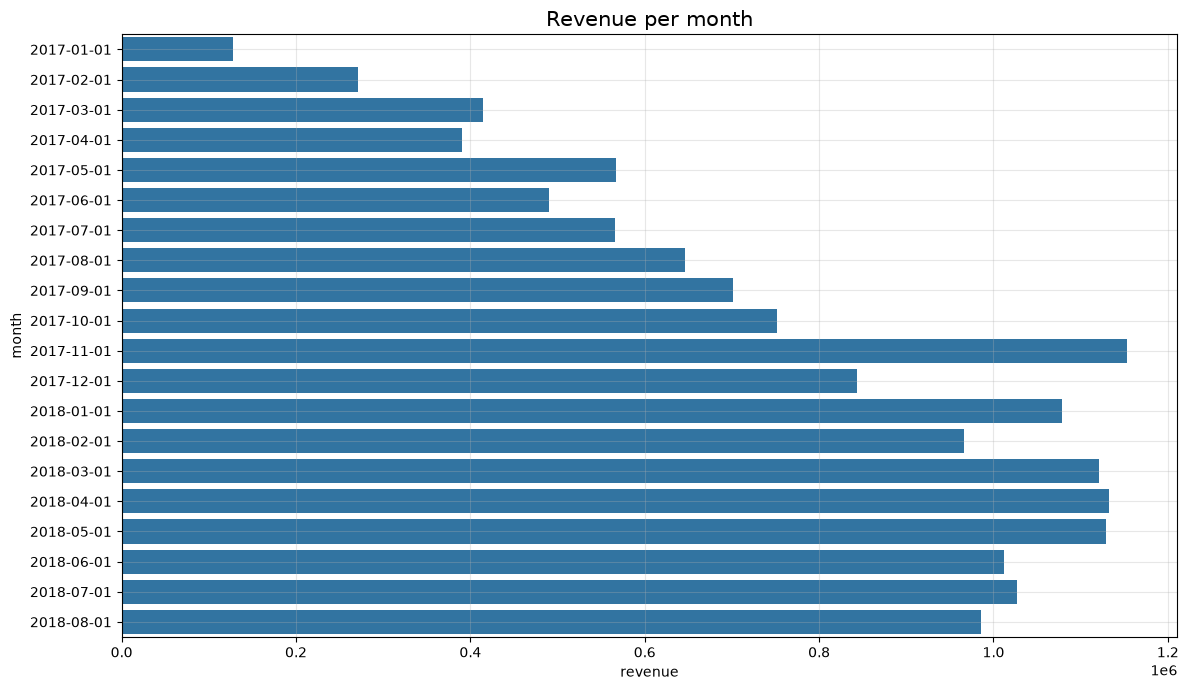

In [161]:
dt = pd.read_sql("select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month", engine)
plt.figure(figsize=(12, 7))
sns.barplot(data=dt, x='revenue', y='month',)
plt.title('Revenue per month', fontsize=15,)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../images/revenue_per_month.png", dpi=150, bbox_inches="tight")

plt.show()


### 📊 Ключевые выводы по графику выручки:

* **Стабильный рост в 2017 году:** Бизнес рос с каждым месяцем. Яркий пик виден в **ноябре 2017 года** — скорее всего, это результат распродаж в «Черную пятницу».
* **Пик и плато весной 2018:** Март, апрель и май стали самыми успешными месяцами за весь период. Выручка стабильно держалась на максимальном уровне (выше 1.1 млн).
* **Летний спад 2018:** Начиная с июня, продажи начинают плавно снижаться и падают ниже 1 млн. 

**Что делать дальше (Гипотеза):** 
Нужно проверить, почему падает выручка летом 2018. Причиной может быть либо сезонное падение **среднего чека**, либо рост **отмен заказов** на этапе доставки.


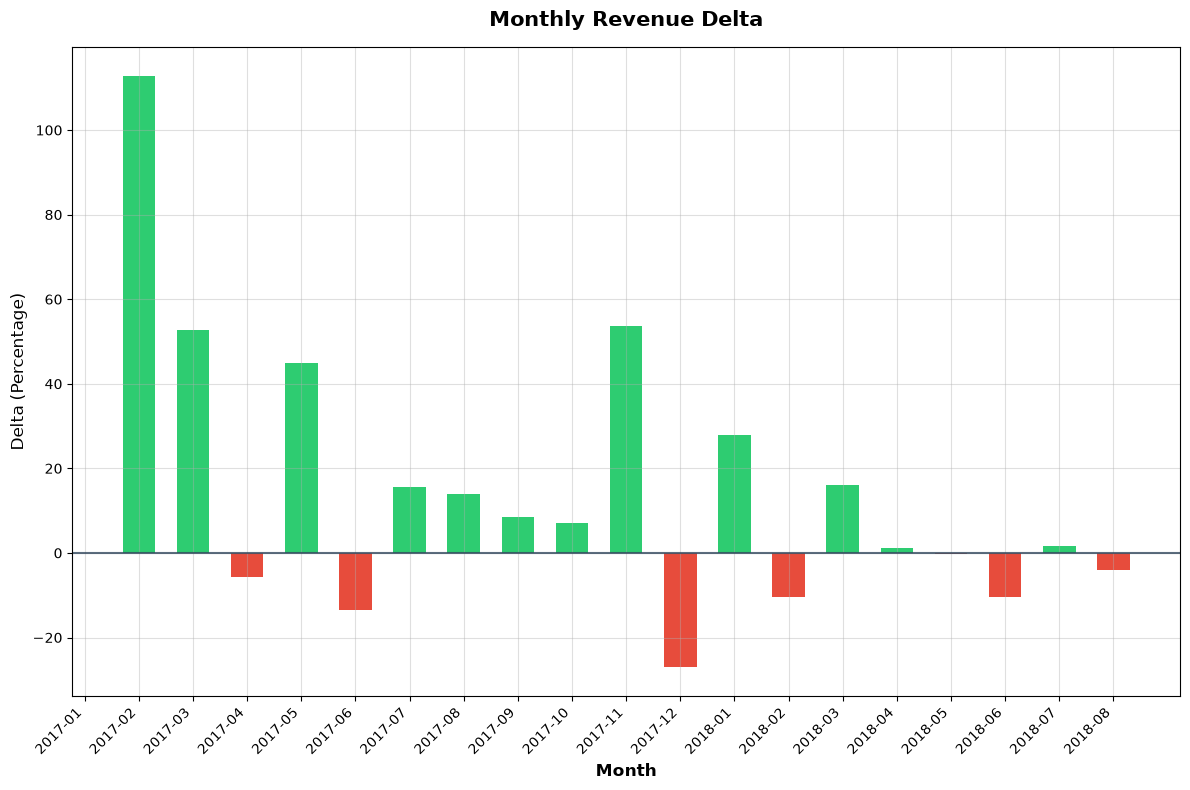

In [4]:
dt = pd.read_sql("with monthly_revenue as (select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month) select month, revenue, (revenue - lag(revenue) over(order by month)) / (lag(revenue) over(order by month)) * 100 as revenue_diff from monthly_revenue", engine)
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in dt['revenue_diff']]
dt['month'] = pd.to_datetime(dt['month'])
plt.figure(figsize=(12, 8))
plt.xlabel('Months', fontsize=15, fontweight='bold')
bars = plt.bar(
    dt['month'].dt.strftime('%Y-%m'), 
    dt['revenue_diff'],
    color=colors,
    edgecolor='none',
    width=0.6
)
plt.grid(alpha=0.4)
plt.axhline(0, color='#34495e', linestyle='-', linewidth=1.5, alpha=0.8)
plt.title('Monthly Revenue Delta', fontsize=15, weight='bold', pad=15)
plt.ylabel('Delta (Percentage)', fontsize=12, rotation=90)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Month', fontsize=12)
plt.tight_layout()
plt.savefig("../images/monthly_rev_delta_pct.png", dpi=150, bbox_inches="tight")
plt.show()

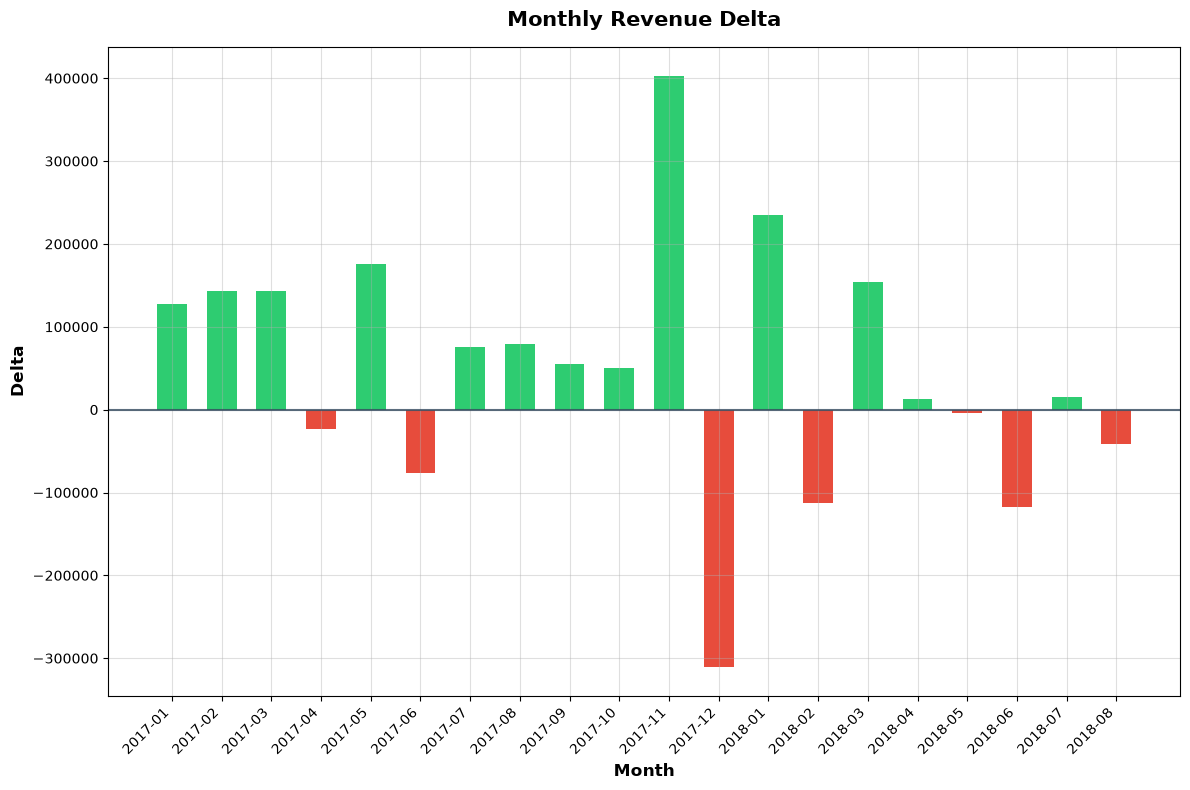

In [20]:
dt = pd.read_sql("with monthly_revenue as (select date_trunc('month', o.order_purchase_timestamp)::date as month, sum(p.payment_value) as revenue from orders_period o join order_payments p on o.order_id = p.order_id inner join orders_delivered d on o.order_id = d.order_id group by month order by month) select month, revenue, (revenue - lag(revenue, 1, 0) over(order by month)) as revenue_diff from monthly_revenue", engine)
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in dt['revenue_diff']]
dt['month'] = pd.to_datetime(dt['month'])
plt.figure(figsize=(12, 8))
plt.xlabel('Months', fontsize=15, fontweight='bold')
bars = plt.bar(
    dt['month'].dt.strftime('%Y-%m'), 
    dt['revenue_diff'],
    color=colors,
    edgecolor='none',
    width=0.6
)
plt.grid(alpha=0.4)
plt.axhline(0, color='#34495e', linestyle='-', linewidth=1.5, alpha=0.8)
plt.title('Monthly Revenue Delta', fontsize=15, weight='bold', pad=15)
plt.ylabel('Delta', fontsize=12, weight='bold', rotation=90)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Month', fontsize=12)
plt.tight_layout()
plt.savefig("../images/monthly_rev_delta_mln.png", dpi=150, bbox_inches="tight")
plt.show()

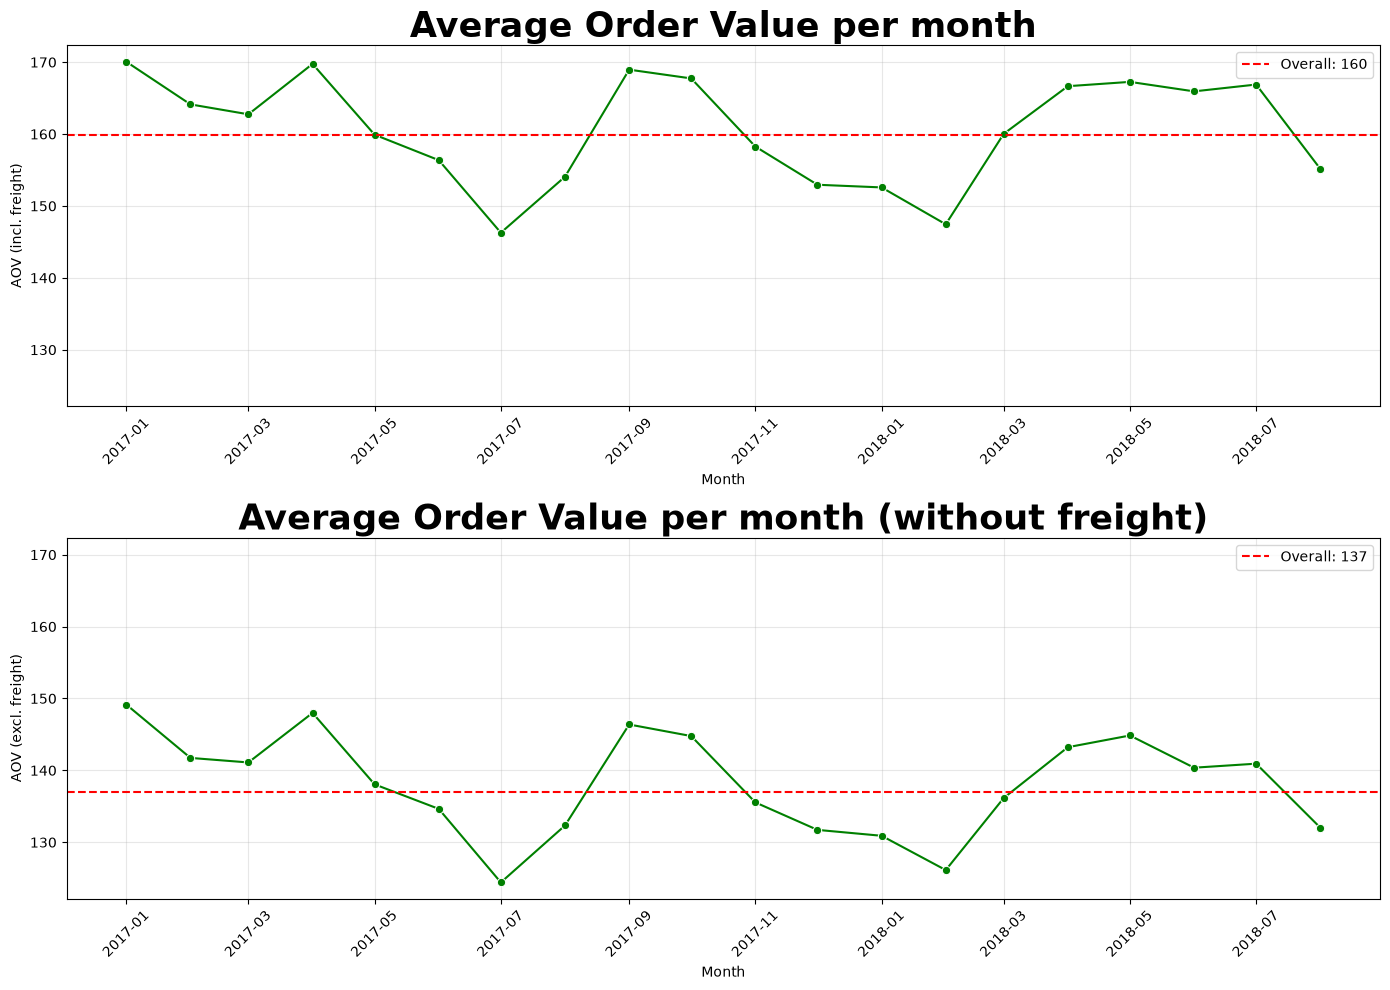

In [6]:
BASE = """
    WITH pay AS (
        SELECT order_id, SUM(payment_value) AS paid
        FROM order_payments
        GROUP BY order_id
    ),
    items AS (
        SELECT order_id, SUM(freight_value) AS freight
        FROM order_items
        GROUP BY order_id
    ),
    orders_base AS (
        SELECT d.order_id,
               DATE_TRUNC('month', d.order_purchase_timestamp)::date AS month,
               COALESCE(pay.paid, 0)      AS paid,
               COALESCE(items.freight, 0) AS freight
        FROM orders_delivered d
        LEFT JOIN pay   ON pay.order_id   = d.order_id
        LEFT JOIN items ON items.order_id = d.order_id
    )
"""

monthly = pd.read_sql(BASE + """
    SELECT month,
           ROUND(AVG(paid), 2)::float           AS aov,
           ROUND(AVG(paid - freight), 2)::float AS aov_ex_freight
    FROM orders_base
    GROUP BY month
    ORDER BY month
""", engine)

overall = pd.read_sql(BASE + """
    SELECT ROUND(AVG(paid), 2)::float           AS aov,
           ROUND(AVG(paid - freight), 2)::float AS aov_ex_freight
    FROM orders_base
""", engine).iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharey=True)

panels = [
    ("aov",            "AOV (incl. freight)",  "Average Order Value per month"),
    ("aov_ex_freight", "AOV (excl. freight)",  "Average Order Value per month (without freight)"),
]

for ax, (col, ylabel, title) in zip(axes, panels):
    sns.lineplot(data=monthly, x="month", y=col, marker="o", color="green", ax=ax)
    ax.axhline(overall[col], color="red", linestyle="--",
               label=f"Overall: {overall[col]:.0f}")
    ax.set_title(title, fontsize=25, weight='bold')
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("../images/aov_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

### Средний чек (AOV) по месяцам

**Метрика:** AOV = сумма платежей (с учетом доставки) / число уникальных заказов. Считается по доставленным заказам за период янв 2017 – авг 2018.

**Общий AOV за период: ~160 $.**

**Наблюдения:**
- Средний чек колеблется в диапазоне **~146–170 $**, то есть около ±8% от общего значения. Резких скачков нет, показатель стабилен.
- На графике заметна волнообразная динамика с периодом около полугода. 
- Это может указывать на сезонность, но данных недостаточно для вывода: в выборке всего 20 месяцев. 

**Вывод по AOV:** средний чек в апреле–июле 2018 года держится на высоком уровне (около 166–167 $) и не снижается, хотя выручка в этот период падает. Значит, спад выручки летом 2018 не объясняется чеком. Остаётся вторая составляющая выручки, число заказов, поэтому дальше проанализируем объёмы продаж по месяцам.

### Объём продаж по месяцам

Выручка равна числу заказов, умноженному на средний чек. Раз чек стабилен, сравним число доставленных заказов по месяцам и посмотрим, совпадает ли его динамика с динамикой выручки.

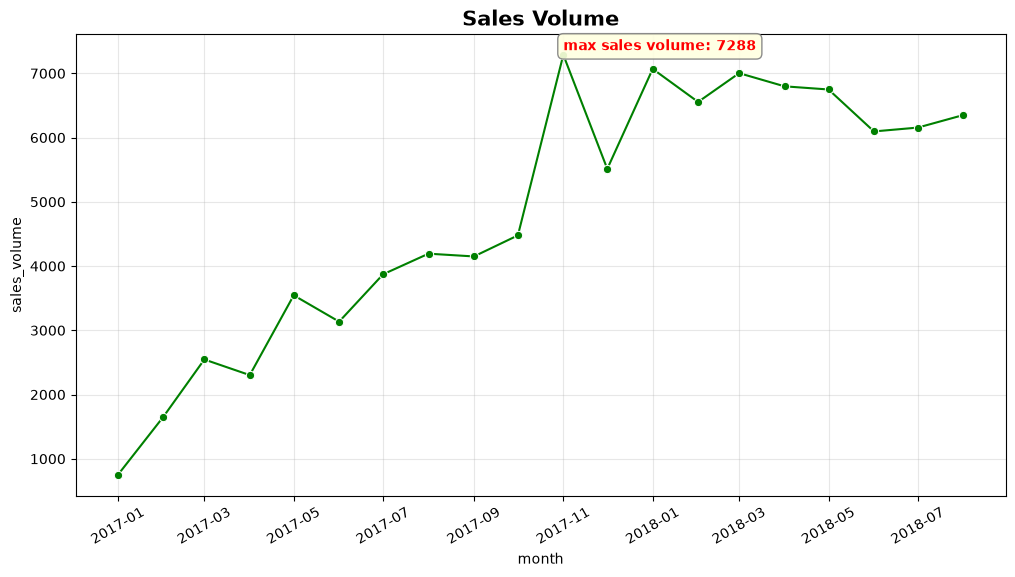

In [163]:
volume_per_month = pd.read_sql("""select date_trunc('month', order_purchase_timestamp)::date as month, count(*) as sales_volume from orders_delivered group by month order by month""", engine)
plt.figure(figsize=(12,6))
sns.lineplot(x=volume_per_month.month, y=volume_per_month.sales_volume,marker='o', color='green')
plt.grid(alpha=0.3)
plt.tick_params(axis='x', rotation=30)
plt.text(volume_per_month[volume_per_month.sales_volume == volume_per_month.sales_volume.max()].month.iloc[0], y = volume_per_month.sales_volume.max() * 1.01, s=f"max sales volume: {volume_per_month.sales_volume.max()}", weight='bold', color='red', bbox=dict(facecolor="lightyellow", edgecolor="gray", boxstyle="round,pad=0.4", alpha=0.9))
plt.title('Sales Volume', fontsize=15, weight='bold')
plt.savefig('../images/sales_volume.png', dpi=150, bbox_inches="tight")
plt.show()

Число заказов росло почти весь 2017 год и достигло пика в ноябре 2017 (7 288 заказов), вероятно, из-за Black Friday. После декабрьского спада оно держится на уровне 6 000–7 000 заказов в месяц.

**Что объясняет просадки выручки летом:**
- **Лето 2017.** Выручка просела только в июне, и главная причина в числе заказов, чек снизился слабее (около −2%). В июле чек был минимальным за весь период, но заказов стало больше, и выручка выросла.
- **Лето 2018.** Чек стабилен (около 166–167 $), а заказы снизились примерно на 10% с мая на июнь и частично восстановились к августу. Значит, летняя просадка 2018 года связана с объёмом продаж, а не с чеком.

Таким образом, во время просадок выручки ведущим фактором оказывается число заказов, а не размер чека.

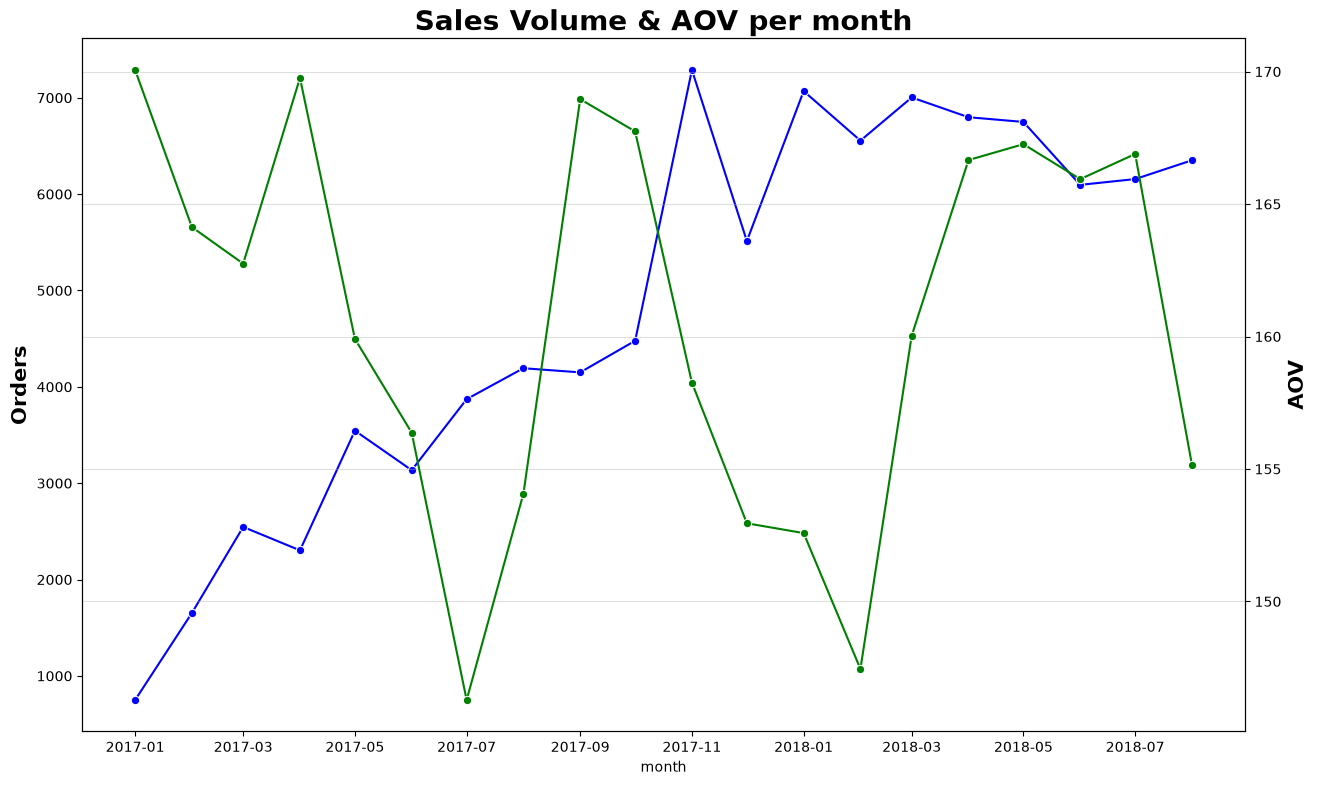

In [8]:
base = pd.read_sql("""
    SELECT DATE_TRUNC('month', d.order_purchase_timestamp)::date AS month,
           COUNT(*)                                AS orders,
           ROUND(AVG(p.paid)::numeric, 2)::float   AS aov,
           ROUND(SUM(p.paid)::numeric, 0)::float   AS revenue
    FROM orders_delivered d
    LEFT JOIN (SELECT order_id, SUM(payment_value) AS paid
               FROM order_payments GROUP BY order_id) p ON p.order_id = d.order_id
    GROUP BY month
    ORDER BY month
""", engine)

base[["orders_pct", "aov_pct", "revenue_pct"]] = base[["orders", "aov", "revenue"]].pct_change() * 100

fig, ax = plt.subplots(figsize=(15, 9))
sns.lineplot(data=base, x='month', y='orders', marker='o', color='blue')
ax.set_ylabel('Orders',fontsize=15, weight='bold')

ax2 = ax.twinx()
sns.lineplot(data=base, x='month', y='aov', marker='o', color='green')
ax2.set_ylabel('AOV', fontsize=15, weight='bold')
plt.grid(alpha=0.4)

plt.title('Sales Volume & AOV per month', fontsize=20, weight='bold')
plt.show()

In [9]:
top_c = pd.read_sql('with cat as (select pc.category_en as category, count(*) as items_sold, COUNT(DISTINCT i.order_id)  as cnt_orders, avg(i.price) as avg_price, sum(i.price) as revenue from orders_delivered d join order_items i on d.order_id = i.order_id join products_clean pc on pc.product_id = i.product_id group by pc.category_en order by revenue desc) select category, items_sold, cnt_orders, round(avg_price, 2) as avg_price, revenue, round(100 * revenue / sum(revenue) over(), 2) as revenue_pct, round(100 * sum(revenue) over (order by revenue desc) / sum(revenue) over (), 2) as cumulative_pct from cat', engine)
top_c

,category,items_sold,cnt_orders,avg_price,revenue,revenue_pct,cumulative_pct
0,health_beauty,9422,8610,130.50,1229557.50,9.33,9.33
1,watches_gifts,5853,5489,198.73,1163187.91,8.83,18.15
2,bed_bath_table,10945,9267,93.46,1022955.77,7.76,25.92
3,sports_leisure,8413,7512,113.24,952661.40,7.23,33.14
4,computers_accessories,7631,6517,116.36,887944.60,6.74,39.88
...,...,...,...,...,...,...,...
69,flowers,33,29,33.64,1110.04,0.01,99.98
70,home_comfort_2,30,24,25.34,760.27,0.01,99.99
71,cds_dvds_musicals,14,12,52.14,730.00,0.01,99.99
72,fashion_childrens_clothes,7,7,74.28,519.95,0.00,100.00


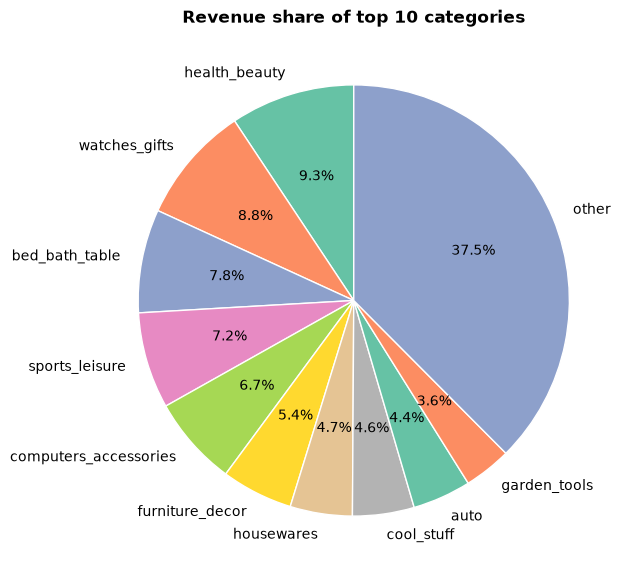

In [10]:
plt.figure(figsize=(7, 7))
top10_c = top_c.head(10).copy()
other = pd.DataFrame({"category": ['other'], 'revenue': [top_c['revenue'].iloc[10:].sum()]})
top = pd.concat([top10_c[['category', 'revenue']], other], ignore_index=True)
plt.pie(
    top["revenue"],
    labels=top["category"],
    autopct="%1.1f%%",          
    startangle=90,  
    colors = sns.color_palette("Set2", len(top)),          
    wedgeprops={"edgecolor": "white"},
)
plt.title("Revenue share of top 10 categories", weight='bold')
plt.savefig("../images/top_10_cats.png", dpi=150, bbox_inches="tight")



### Топ-10 категорий по выручке

**Метрика:** выручка = сумма цен товаров (`price`, без доставки) по доставленным заказам за период янв 2017 – авг 2018. Платежи по категориям не разделить, потому что платёж относится к заказу целиком, а в заказе могут быть товары из разных категорий.

**Выводы:**
- Выручка распределена достаточно равномерно: нет категории, которая занимала бы больше 10%. Лидеры: `health_beauty` (9,3%), `watches_gifts` (8,8%) и `bed_bath_table` (7,8%).
- Топ-3 категории дают около 26% выручки, топ-10 дают 62,5%. Остальные 37,5% приходятся на категории вне топ-10 (всего их около 70).
- Выручка диверсифицирована по категориям: она не держится на одной-двух, а распределена между многими. Самая крупная категория даёт 9,3%, и даже топ-3 вместе дают около 26%. Поэтому падение спроса в одной категории не обрушит выручку, зависимость от любой из них невысокая.

**Ограничения:** доля товаров без категории (`unknown`) ~ 1,29% и точное число категорий в хвосте 64. Доля в выручке не равна доле в заказах: категория с дорогими товарами может занимать высокое место по деньгам, но продаваться редко.

### Объём продаж и цена по категориям

Выручка категории равна числу проданных позиций, умноженному на среднюю цену. Посмотрим на обе составляющие вместе, чтобы понять, какие категории зарабатывают за счёт объёма, а какие за счёт цены.

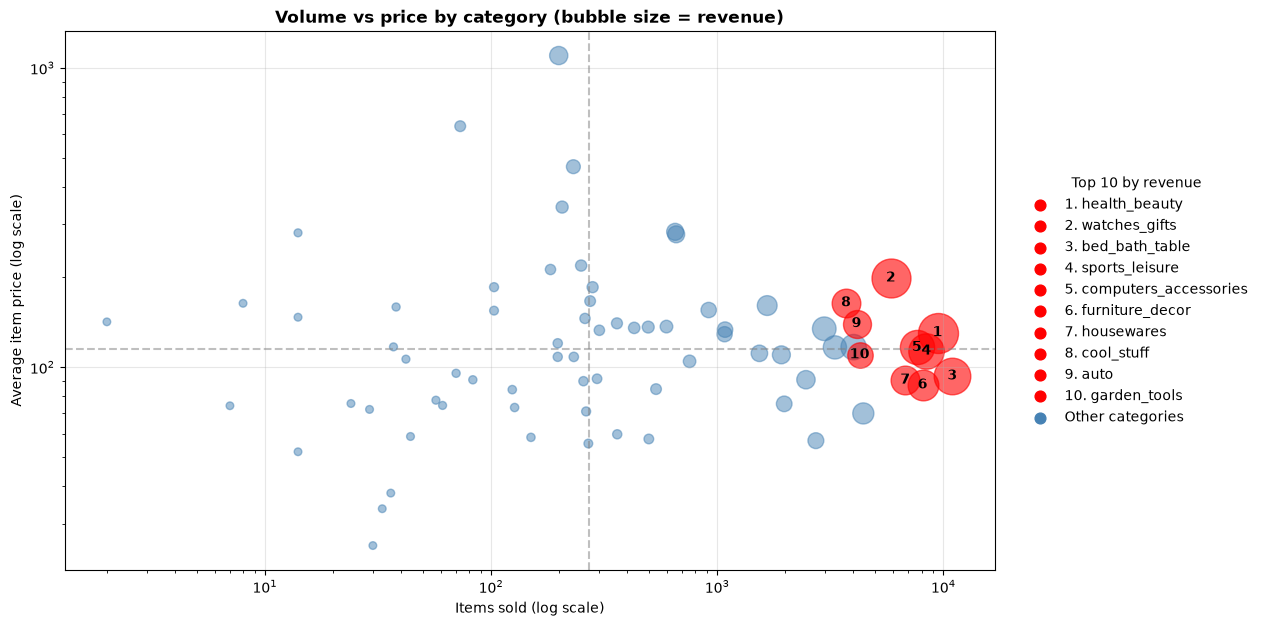

In [11]:
df = top_c.copy()
for col in ["revenue", "items_sold", "avg_price"]:
    df[col] = df[col].astype(float)

df = df.sort_values("revenue", ascending=False)          
df["size"] = df["revenue"] / df["revenue"].max() * 800 + 30   

top10 = df.head(10)       
others = df.iloc[10:]    

x_med = df["items_sold"].median()
y_med = df["avg_price"].median()

plt.figure(figsize=(12, 7))

plt.scatter(others["items_sold"], others["avg_price"],
            s=others["size"], color="steelblue", alpha=0.5)

for i, (cat, x, y, size) in enumerate(
        zip(top10["category"], top10["items_sold"], top10["avg_price"], top10["size"]), start=1):
    plt.scatter(x, y, s=size, color="red", alpha=0.6)                       
    plt.text(x, y, str(i), ha="center", va="center", color="black", fontweight="bold")
    plt.scatter([], [], s=60, color="red", label=f"{i}. {cat}")            

plt.scatter([], [], s=60, color="steelblue", label="Other categories")      

# линии медиан
plt.axvline(x_med, color="gray", linestyle="--", alpha=0.5)   
plt.axhline(y_med, color="gray", linestyle="--", alpha=0.5) 

# оформление
plt.xscale("log")
plt.yscale("log")
plt.title("Volume vs price by category (bubble size = revenue)", weight="bold")
plt.xlabel("Items sold (log scale)")
plt.ylabel("Average item price (log scale)")
plt.grid(alpha=0.3)
plt.legend(title="Top 10 by revenue", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.savefig("../images/volume_vs_avg_price.png", dpi=150, bbox_inches="tight")
plt.show()

**Как читать график:** каждая точка это категория, размер точки показывает выручку. Красные точки с номерами это топ-10 по выручке, синие остальные категории. Пунктирные линии проходят по медианам. Обе оси логарифмические, потому что значения различаются в десятки раз.

**Выводы:**
- Все категории из топ-10 расположены в правой части графика: по числу проданных позиций они заметно опережают остальные категории. Это главная причина их высокой выручки.
- По цене топ-10 неоднороден. Часть категорий продаёт товары дороже медианы (например, `watches_gifts`), а часть дешевле медианы: `bed_bath_table`, `housewares`, `furniture_decor`.
- Значит, выручку лидеров обеспечивает прежде всего объём, а не высокая цена. Категории с низкой ценой позиции зарабатывают за счёт большого числа продаж, категории с высокой ценой получают дополнительный вклад от стоимости товаров.
- Для бизнеса это значит, что рост выручки в основном зависит от числа заказов, поэтому важнее привлекать покупателей и удерживать спрос, чем поднимать цены.

### **2. Анализ логистики: срок доставки, доля опозданий, влияние на оценку, штаты**


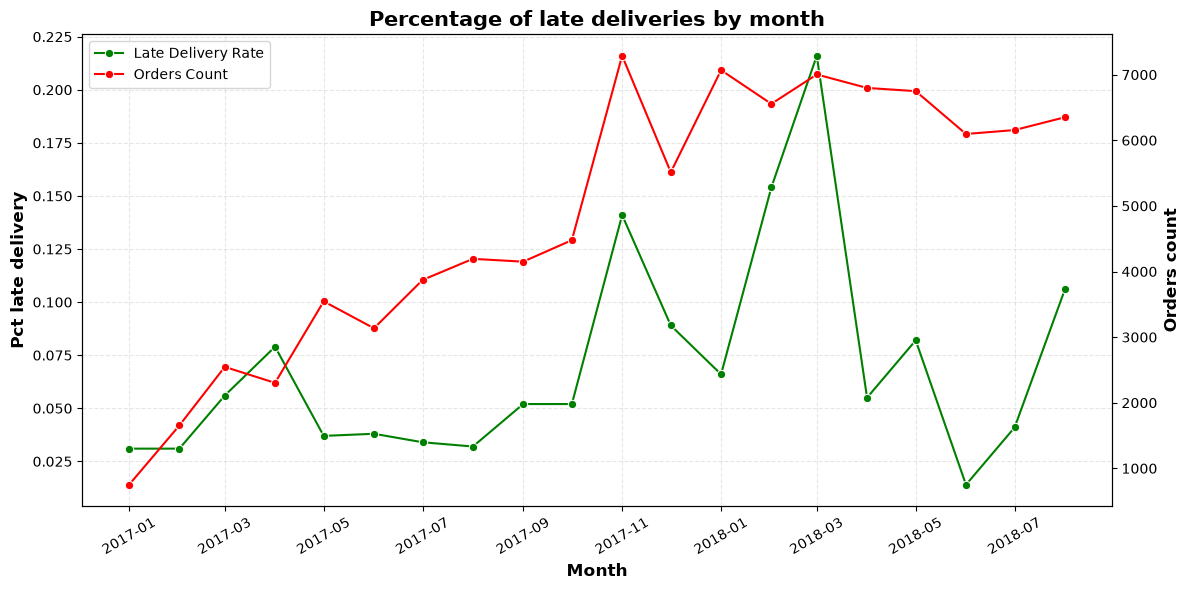

In [164]:
late = pd.read_sql("""select date_trunc('month', order_approved_at)::date as month, round(avg((order_estimated_delivery_date < order_delivered_customer_date)::int), 3) as late_delivery from orders_delivered group by month order by month""", engine)
fig, ax1 = plt.subplots(figsize=(12, 6))
line1 = sns.lineplot(data=late, x='month', y='late_delivery', marker='o', color='green', label='Late Delivery Rate')
ax1.grid(alpha=0.3, linestyle='--')
ax1.set_title('Percentage of late deliveries by month', fontsize=15, weight='bold')
ax1.tick_params(axis='x', rotation=30)
ax1.set_xlabel('Month', fontsize=12, weight='bold')
ax1.set_ylabel('Pct late delivery', fontsize=12, weight='bold')

ax2 = ax1.twinx()
line2 = sns.lineplot(data=base, x='month', y='orders', marker='o', color='red', label='Orders Count')
ax2.set_ylabel('Orders count', fontsize=12, weight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
ax2.get_legend().remove()

plt.tight_layout()
plt.savefig("../images/percentage_late_del.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
correlation_l = base['orders'].corr(late.late_delivery, 'spearman')
print(f"Корреляция между объемом заказов и задержками: {correlation_l:.4f}")



Корреляция между объемом заказов и задержками: 0.6238


Дополнительно была исследована зависимость между объемом продаж и качеством работы логистики. Коэффициент корреляции Спирмена составил ~ 0.62, что говорит о сильной прямой связи. Проблемы с доставкой напрямую вызваны перегрузкой инфраструктуры в пиковые месяцы — логистическая сеть Olist оказалась не готова к быстрому масштабированию бизнеса маркетплейса

### Анализ задержек доставок и общего количества доставок в месяц

* **«Болезни роста» e-commerce:** До октября 2017 года логистика справлялась с нагрузкой, но взрывной рост заказов в конце года спровоцировал системные сбои.
* **Пик «Черной пятницы» (Ноябрь 2017):** Резкий скачок заказов (>7000) привел к коллапсу инфраструктуры — доля опозданий подскочила до **14%**.
* **Успешная оптимизация (Май 2018):** Компания провела работу над ошибками, снизив процент опозданий до минимума (**~1%**) даже при высокой нагрузке на маркетплейс.
* **Влияние на бизнес:** Высокий уровень задержек влияет на оценки клиентов и на Churn Rate, который у Olist и так высокий (~ 97%)


Изучим корреляцию задержек доставок и оценок пользователей

In [14]:
reviews = pd.read_sql("""select date_trunc('month', order_delivered_customer_date) :: date as month, round(avg(review_score), 2) as avg_score, round(avg((order_estimated_delivery_date < order_delivered_customer_date)::int), 3) as late_delivery from orders_delivered d left join order_reviews_clean r on r.order_id = d.order_id group by month order by month""", engine)
correlation = reviews['avg_score'].corr(reviews['late_delivery'], method='spearman')
print(f"Коэффициент корреляции Спирмена: {correlation:.4f}")

Коэффициент корреляции Спирмена: -0.6243


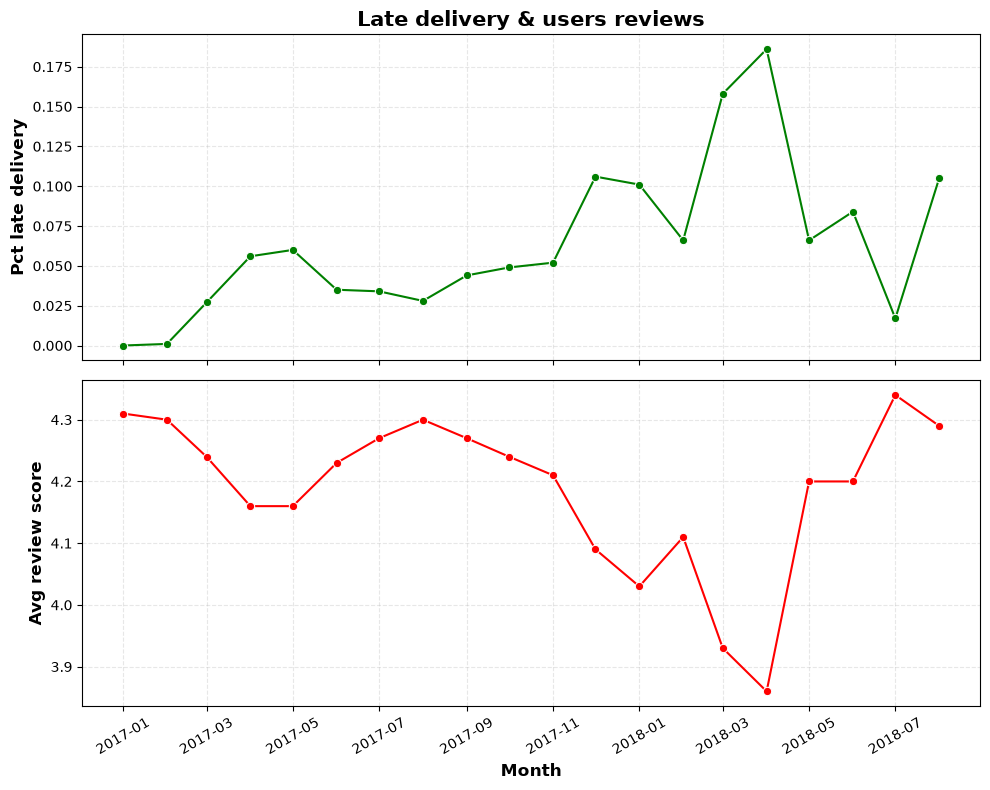

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.lineplot(data=reviews, x="month", y="late_delivery", marker="o",
             color="green", ax=axes[0])
axes[0].set_title("Late delivery & users reviews", fontsize=15, weight="bold")
axes[0].set_ylabel("Pct late delivery", fontsize=12, weight="bold")
axes[0].set_xlabel("")
axes[0].grid(alpha=0.3, linestyle="--")

sns.lineplot(data=reviews, x="month", y="avg_score", marker="o",
             color="red", ax=axes[1])
axes[1].set_ylabel("Avg review score", fontsize=12, weight="bold")
axes[1].set_xlabel("Month", fontsize=12, weight="bold")
axes[1].grid(alpha=0.3, linestyle="--")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../images/late_delivery_vs_reviews.png", dpi=150, bbox_inches="tight")
plt.show()

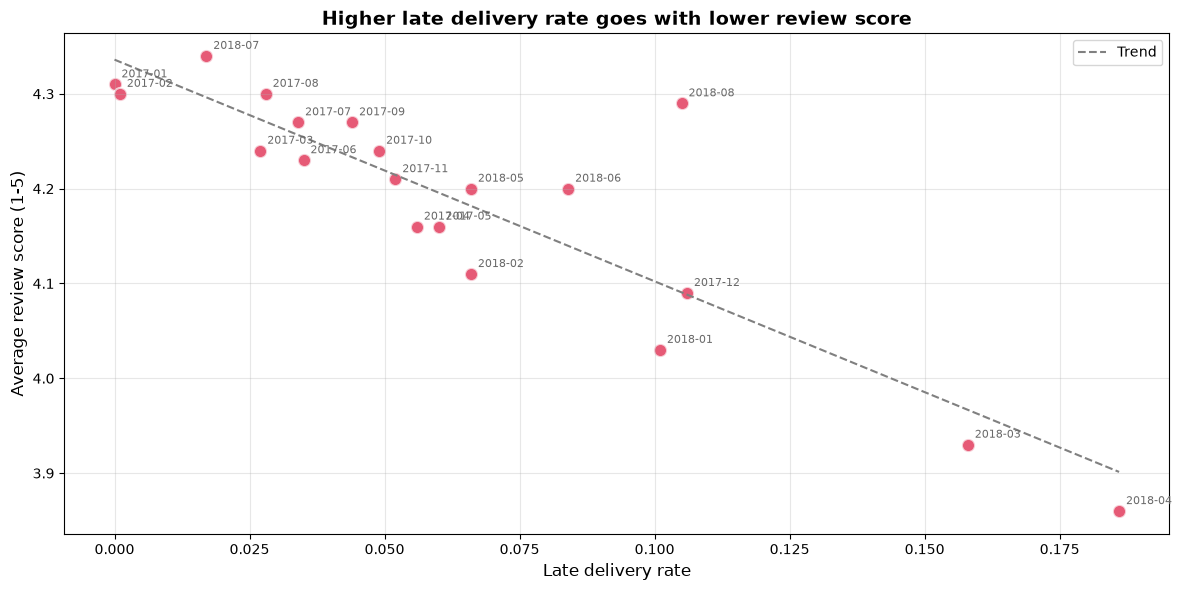

In [165]:
import numpy as np

x = reviews["late_delivery"]       
y = reviews["avg_score"]           

plt.figure(figsize=(12, 6))
plt.scatter(x, y, s=90, color="crimson", alpha=0.7, edgecolor="white", linewidth=1.5)

k, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, k * xs + b, color="gray", linestyle="--", label="Trend")
for xi, yi, m in zip(x, y, reviews["month"]):
    plt.annotate(pd.to_datetime(m).strftime("%Y-%m"), (xi, yi),
                 xytext=(5, 5), textcoords="offset points", fontsize=8, color="dimgray")
plt.title("Higher late delivery rate goes with lower review score", fontsize=14, weight="bold")
plt.xlabel("Late delivery rate", fontsize=12)
plt.ylabel("Average review score (1-5)", fontsize=12)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("../images/late_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()

### Влияние логистики на удовлетворенность клиентов

Для анализа взаимосвязи качества доставки и оценок пользователей данные были агрегированы по **месяцу фактического получения заказа клиентом** (`order_delivered_customer_date`), так как пользователь оценивает уже пережитый опыт доставки.

#### Результаты расчетов
* **Коэффициент корреляции Спирмена:** ` -0.6243 `
* **Характер связи:** Заметная (сильная) отрицательная взаимосвязь.

#### Главные выводы для бизнеса
* **Доставка решает всё:** Как только у Olist растут задержки в логистике, средние отзывы падают.
* **Логистика — слабое место маркетплейса:** На общую оценку клиента влияет много вещей: брак товара, высокая цена, плохой сервис. Но именно несоответствие запланированнной дате доставки имеет серьезное влияние на оценки юзеров.  

### Распределение времени доставки

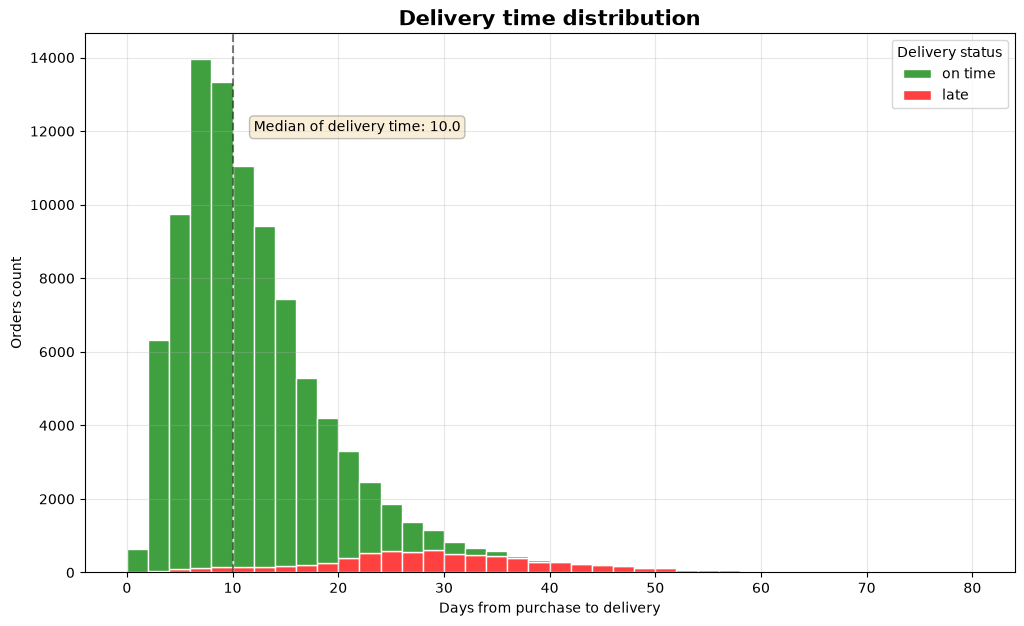

In [159]:
deliv_time = pd.read_sql("""select order_delivered_customer_date::date - order_purchase_timestamp::date as delivery_time, case when order_delivered_customer_date > order_estimated_delivery_date then 'late' else 'on time' end as estimated_delivery from orders_delivered""", engine)
med = deliv_time.delivery_time.median()
plt.figure(figsize=(12, 7))

ax = sns.histplot(data=deliv_time, x='delivery_time', bins=40, hue='estimated_delivery', multiple="stack", binrange=(0, 80), palette={"on time": "green", "late": "red"}, edgecolor='white')
plt.title("Delivery time distribution", fontsize=15, weight="bold")
plt.xlabel("Days from purchase to delivery")
plt.ylabel("Orders count")
plt.grid(alpha=0.3)
plt.axvline(x=med, linestyle='--', alpha=0.5, color='black')
plt.text(x=med*1.2, y=12000, s=f'Median of delivery time: {med}', bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5, edgecolor="gray"))
ax.get_legend().set_title("Delivery status")
plt.savefig('../images/Delivery_days_distr', dpi=150, bbox_inches="tight")


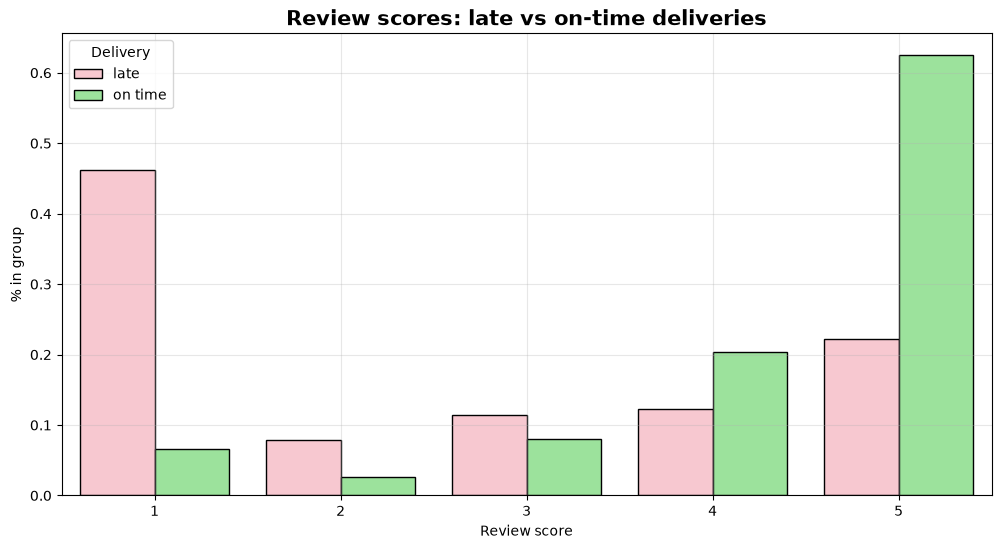

In [153]:
revs = pd.read_sql("""
    with base as (select CASE WHEN order_estimated_delivery_date < order_delivered_customer_date then 'late' 
            ELSE 'on time' end as delivery_status,
        review_score::int
        from orders_delivered d
        JOIN order_reviews_clean c
        ON d.order_id = c.order_id),

    groupped as (select delivery_status, review_score, count(*) as orders
        from base
        group by delivery_status, review_score)
        
    select delivery_status, review_score, orders, orders / sum(orders) over (partition by delivery_status) as pct_in_group
    from groupped 
        """, engine)
plt.figure(figsize=(12,6))
sns.barplot(data=revs, x='review_score', y='pct_in_group', hue='delivery_status', palette={"on time": "lightgreen", "late": "pink"}, edgecolor='black')
plt.grid(alpha=0.3)
plt.title("Review scores: late vs on-time deliveries", fontsize=15, weight="bold")
plt.xlabel('Review score')
plt.ylabel('% in group')
plt.legend(title="Delivery")
plt.savefig('../images/on_time_del_vs_late_del', dpi=150, bbox_inches="tight")
plt.show()



### Срок доставки и оценки клиентов

- Большинство заказов доставляется за **5–15 дней** (пик около 8 дней, медиана 10 дней).
- У распределения длинный правый хвост: часть заказов едет 30 дней и дольше. Опоздания (красное) почти полностью сосредоточены в этом хвосте, а при доставке до 15 дней их мало.
- Общая доля опозданий: 8,13% заказов.

- **Оценки сильно различаются между группами.** У доставленных вовремя около 62% оценок «5», а у опоздавших около 22%.
- **Низкие оценки (1–2):** у опоздавших это примерно 54% отзывов, у доставленных вовремя около 9%. Оценка «1» у опоздавших встречается примерно в 7 раз чаще (около 46% против 6–7%).
- Средняя оценка: вовремя 4,29, с опозданием 2,57.

**Вывод:** опоздание резко повышает шанс плохого отзыва, значит, соблюдение обещанных сроков напрямую влияет на удовлетворённость клиентов.

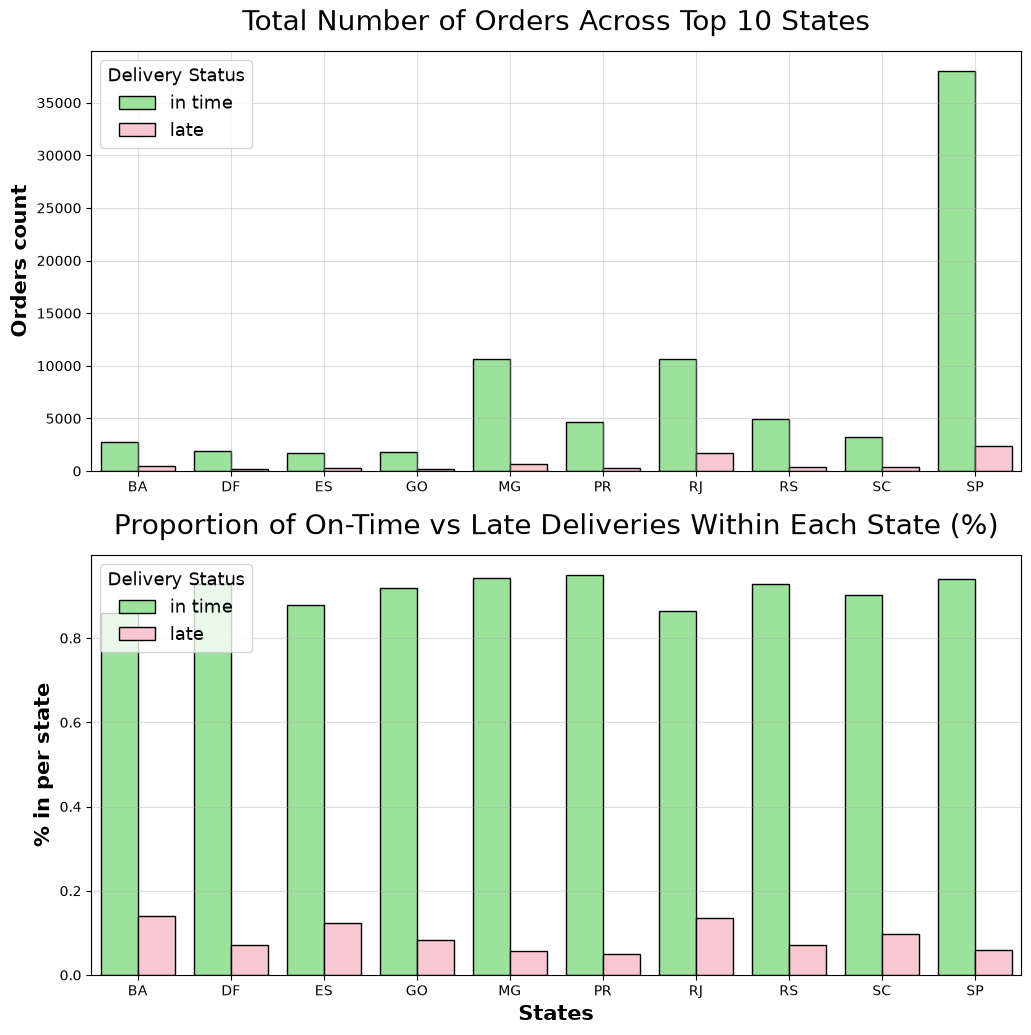

In [155]:
states = pd.read_sql("""
with base as (SELECT
    customer_state as state,
    case when order_estimated_delivery_date < order_delivered_customer_date then 'late' 
    else 'in time' end as delivery_status,
    order_delivered_customer_date::date - order_purchase_timestamp::date as del_time
    from orders_delivered d join customers c on d.customer_id = c.customer_id),

aggregated as (select state, delivery_status,
    count(*) as orders,
    avg(del_time) as avg_del_time
from base
group by state, delivery_status
order by state, delivery_status)

select state, delivery_status, orders, orders :: numeric / sum(orders) over(partition by state) as pct_in_group
from aggregated
    """, engine)

top10_state_names = (
    states.groupby('state')['orders']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

top10states = states[states['state'].isin(top10_state_names)].copy()
fig, axes = plt.subplots(2,1, figsize=(12, 12))
sns.barplot(data=top10states, x='state', y='orders', hue='delivery_status', ax=axes[0], palette={"in time": "lightgreen", "late": "pink"}, edgecolor='black')
axes[0].set_xlabel('')
axes[0].set_ylabel('Orders count', fontsize=15, weight='bold')
axes[0].set_title('Total Number of Orders Across Top 10 States', fontsize=20, pad=15)
axes[0].legend(title='Delivery Status', title_fontsize=13, fontsize=13)
axes[0].grid(alpha=0.4)
axes[1].grid(alpha=0.4)
sns.barplot(data=top10states, x='state', y='pct_in_group', hue='delivery_status', ax=axes[1], palette={"in time": "lightgreen", "late": "pink"}, edgecolor='black')
axes[1].set_xlabel('States', fontsize=15, weight='bold')
axes[1].set_ylabel('% in per state', fontsize=15, weight='bold')
axes[1].set_title('Proportion of On-Time vs Late Deliveries Within Each State (%)', fontsize=20, pad=15)
axes[1].legend(title='Delivery Status', loc='upper left', title_fontsize=13, fontsize=13)
plt.savefig('../images/delivery_across_states', dpi=150, bbox_inches="tight")
plt.show()




### Анализ логистики 

#### 1. Объемы заказов по штатам (Абсолютные показатели)
* **SP (Сан-Паулу):** Абсолютный лидер рынка с колоссальным отрывом (более 35 000 заказов).
* **MG (Минас-Жерайс) и RJ (Рио-де-Жанейро):** Крупные региональные рынки второго эшелона (около 10 000 заказов каждый).
* **Остальные 7 штатов:** Низкие объемы, не превышающие 5 000 заказов на каждый регион.

#### 2. Качество доставки (Относительные показатели)
* **Общий тренд:** Во всех штатах доля своевременных доставок превышает 80%.
* **Лидеры по эффективности:** **SP**, **PR** и **MG** имеют минимальный уровень задержек (около 5–6%).
* **Аутсайдеры по качеству:** **BA**, **RJ** и **ES** демонстрируют самую высокую долю опозданий (примерно 12–14%).

#### 3. Ключевые точки внимания для Olist
* **Критическая зона (RJ):** Сочетает в себе высокий объем заказов и высокий процент опозданий. 
* **Стабильная база (SP):** Самый крупный рынок эффективно справляется с нагрузкой, сохраняя минимальный процент брака доставки.
